# 📘 08 — NumPy
*Part of the Full Stack Data Science & AI booklet. Run cells top to bottom (Shift + Enter). Install libraries first: `pip install -r ../requirements.txt`.*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, sys, math, random, json, time, copy, warnings
from IPython.display import display
warnings.filterwarnings("ignore")

# 9️⃣ NumPy — Fast numerical computing
NumPy gives the **ndarray**: a grid of same-type numbers that is 10–100× faster than lists and supports whole-array maths (no loops).
Install: `pip install numpy`
## 9.1 Creating arrays

In [2]:
import numpy as np

a = np.array([1, 2, 3, 4])
m = np.array([[1, 2, 3], [4, 5, 6]])
print(a, m, sep="\n")
print(m.shape, m.ndim, m.size, m.dtype)

print(np.zeros((2, 3)), np.ones(3), np.full((2, 2), 7), np.eye(3), sep="\n")
print(np.arange(0, 10, 2), np.linspace(0, 1, 5))
np.random.seed(42)
print(np.random.rand(3), np.random.randint(1, 100, 5), np.random.randn(3))

[1 2 3 4]
[[1 2 3]
 [4 5 6]]
(2, 3) 2 6 int64
[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1.]
[[7 7]
 [7 7]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[0 2 4 6 8] [0.   0.25 0.5  0.75 1.  ]
[0.37454012 0.95071431 0.73199394] [61 21 83 87 75] [-2.01096289 -0.49280342  0.39257975]


#### 🔍 How it works
- `np.array(list)` makes an array; `.shape` (rows, cols), `.ndim`, `.size`, `.dtype` describe it.
- `np.random.seed(42)` fixes the randomness so results can be reproduced; `rand` = uniform 0–1; `randint(low, high, n)`; `randn` = normal distribution.
#### 💼 Where it's used
NumPy is the foundation of Pandas, scikit-learn, TensorFlow and PyTorch. Random seeds are essential for **reproducible experiments**.

### 9.1b dtype, linspace, arange — key array builders
- `np.array([1,2,3,4,5.9], dtype=int)` **truncates** decimals (5.9 → 5). With `float` all become floats.
- `np.arange(start, stop, step)` → like `range` but supports decimals. `np.linspace(start, stop, n)` → exactly **n evenly spaced points including both ends** (that's why you get decimals).

In [3]:
print(np.array([1, 2, 3, 4, 5.9], dtype=float))
print(np.array([1, 2, 3, 4, 5.6], dtype=int))
print(np.linspace(0, 16, 10).round(2))        # 10 points from 0 to 16 (step = 16/9)
print(np.arange(0, 10, 2), np.arange(0, 1, 0.25))
print(np.zeros(5), np.ones(5), np.zeros((2, 2), dtype=int))
a = np.array([10, 20, 30]); print(a.dtype, a.astype(float).dtype, a.nbytes, "bytes")

[1.  2.  3.  4.  5.9]
[1 2 3 4 5]
[ 0.    1.78  3.56  5.33  7.11  8.89 10.67 12.44 14.22 16.  ]
[0 2 4 6 8] [0.   0.25 0.5  0.75]
[0. 0. 0. 0. 0.] [1. 1. 1. 1. 1.] [[0 0]
 [0 0]]
int64 float64 24 bytes


#### 🔍 How it works / 💼 Where it's used
- **Homogeneous** arrays (one dtype) are what make NumPy fast; `astype` converts types, `nbytes` tells memory used.
- `linspace` creates x-values for **plotting curves**; `zeros/ones` create initial weight/bias arrays in ML; `arange` indexes data.

## 9.2 Indexing, slicing, boolean masks

In [4]:
m = np.arange(1, 13).reshape(3, 4)
print(m)
print(m[1, 2], m[0], m[:, 1], m[0:2, 1:3])
print(m[m > 6])                 # boolean mask
m2 = m.copy(); m2[m2 % 2 == 0] = 0; print(m2)
print(np.where(m > 6, "big", "small"))
print(m[[0, 2], [1, 3]])        # fancy indexing

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
7 [1 2 3 4] [ 2  6 10] [[2 3]
 [6 7]]
[ 7  8  9 10 11 12]
[[ 1  0  3  0]
 [ 5  0  7  0]
 [ 9  0 11  0]]
[['small' 'small' 'small' 'small']
 ['small' 'small' 'big' 'big']
 ['big' 'big' 'big' 'big']]
[ 2 12]


#### 🔍 How it works
- `m[1, 2]` → row 1, column 2. `m[:, 1]` → whole column 1. `m[0:2, 1:3]` → a block.
- **Boolean mask:** `m > 6` creates a True/False array; `m[m > 6]` keeps only the True ones (filtering without a loop!).
- `np.where(cond, a, b)` = vectorised if/else. **Fancy indexing** `m[[0,2],[1,3]]` picks the points (0,1) and (2,3).
#### 💼 Where it's used
The same mask idea powers Pandas filtering `df[df.marks > 80]`; used to clip outliers, select rows, apply conditions to millions of values instantly.

## 9.3 Operations, broadcasting, aggregates

In [5]:
a, b = np.array([1, 2, 3]), np.array([10, 20, 30])
print(a + b, a * b, a ** 2, b / a)
print(a + 100)                                   # broadcasting: scalar stretched
print(np.array([[1], [2], [3]]) + np.array([10, 20, 30]))   # column + row

m = np.array([[1, 2, 3], [4, 5, 6]])
print(m.sum(), m.sum(axis=0), m.sum(axis=1))     # axis=0 down columns, axis=1 across rows
print(m.mean(), m.std(), m.min(), m.max(), m.argmax())
print(np.median(m), np.percentile(m, 75), np.cumsum(m))
print(m.T, m.reshape(3, 2), m.flatten(), sep="\n")
print(np.dot(m, m.T))                            # matrix multiplication
print(np.concatenate([a, b]), np.vstack([a, b]), np.hstack([a, b]))
print(np.sort([3, 1, 2]), np.unique([1, 1, 2, 3, 3]))

[11 22 33] [10 40 90] [1 4 9] [10. 10. 10.]
[101 102 103]
[[11 21 31]
 [12 22 32]
 [13 23 33]]
21 [5 7 9] [ 6 15]
3.5 1.707825127659933 1 6 5
3.5 4.75 [ 1  3  6 10 15 21]
[[1 4]
 [2 5]
 [3 6]]
[[1 2]
 [3 4]
 [5 6]]
[1 2 3 4 5 6]
[[14 32]
 [32 77]]
[ 1  2  3 10 20 30] [[ 1  2  3]
 [10 20 30]] [ 1  2  3 10 20 30]
[1 2 3] [1 2 3]


#### 🔍 How it works
- **Broadcasting:** NumPy stretches smaller arrays to match bigger ones, so `a + 100` adds 100 to every element, and a column `+` a row creates a full table.
- `axis=0` → compute **down the columns**; `axis=1` → **across the rows**. `argmax()` returns the *position* of the largest value.
- `np.dot(m, m.T)` = matrix multiplication (the core operation inside every neural network). `.T` transposes; `reshape` changes shape without changing data.
#### 💼 Where it's used
Normalising data `(x - x.mean()) / x.std()`, computing predictions `X @ weights`, image processing — all with **no Python loops**.

## 9.4 Why NumPy? Speed test

In [6]:
import time
size = 2_000_000
lst = list(range(size)); arr = np.arange(size)
t = time.time(); [x * 2 for x in lst]; t1 = time.time() - t
t = time.time(); arr * 2; t2 = time.time() - t
print(f"list: {t1:.4f}s | numpy: {t2:.4f}s | numpy is ~{t1/max(t2,1e-9):.0f}x faster")

list: 0.0694s | numpy: 0.0046s | numpy is ~15x faster


#### 🔍 How it works / 💼 Where it's used
A Python list stores a **pointer to each number object**; a NumPy array stores raw numbers **side by side in memory** and loops run in compiled C. That's why NumPy is often **10–100× faster**. On big data this is the difference between 2 seconds and 2 minutes.

## 🚀 Mini Project 6: Image as a NumPy array + IPL-style analysis
An image is just a 3D array: `(height, width, 3 colour channels)`.

Image shape: (100, 200, 3)


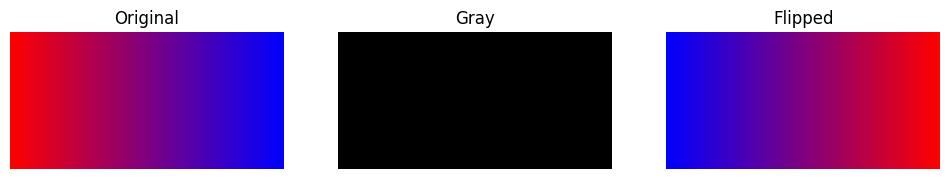

Total: {np.str_('Kohli'): np.int64(210), np.str_('Rohit'): np.int64(307), np.str_('Dhoni'): np.int64(203), np.str_('Gill'): np.int64(200), np.str_('Pant'): np.int64(463)}
Best average: Pant
Centuries-ish (>=50) per player: [2 4 2 2 5]


In [7]:
import matplotlib.pyplot as plt
# Make a small synthetic "image": red-to-blue gradient
h, w = 100, 200
img = np.zeros((h, w, 3))
img[:, :, 0] = np.linspace(1, 0, w)     # red fades
img[:, :, 2] = np.linspace(0, 1, w)     # blue grows
print("Image shape:", img.shape)

gray = img.mean(axis=2)                 # to grayscale
flipped = img[:, ::-1]                  # mirror
fig, ax = plt.subplots(1, 3, figsize=(12, 2.5))
for a_, im, t in zip(ax, [img, gray, flipped], ["Original", "Gray", "Flipped"]):
    a_.imshow(im, cmap="gray" if im.ndim == 2 else None); a_.set_title(t); a_.axis("off")
plt.show()
# With a real photo:  from PIL import Image; arr = np.array(Image.open("photo.jpg"))

# IPL-style: runs of 5 players in 6 matches
np.random.seed(1)
runs = np.random.randint(0, 100, (5, 6))
players = np.array(["Kohli", "Rohit", "Dhoni", "Gill", "Pant"])
print("Total:", dict(zip(players, runs.sum(axis=1))))
print("Best average:", players[runs.mean(axis=1).argmax()])
print("Centuries-ish (>=50) per player:", (runs >= 50).sum(axis=1))

#### 🔍 How the image and the stats work
- An **image is a 3-D array** `(height, width, 3)` — each pixel has 3 numbers (Red, Green, Blue) from 0 to 1 (or 0–255). `img[:, :, 0]` = the red channel.
- `img.mean(axis=2)` averages the 3 colour channels → a **grayscale** image (2-D). `img[:, ::-1]` reverses the columns → a **mirror**.
- `imshow` draws an array as pixels (`cmap="gray"` for single channel).
- IPL analysis: rows = players, columns = matches. `runs.sum(axis=1)` = total per player; `runs.mean(axis=1).argmax()` = index of the best average; `(runs >= 50).sum(axis=1)` = count of 50+ scores (a boolean array adds up as 1s).
#### 💼 Where it's used
Computer vision starts here (every photo fed to a neural network is such an array). The player/match table is the same shape as any sales-by-store-by-month data.

### 🧪 Practice (Section 9)
1. Create a 5×5 matrix with 1 on the border and 0 inside. 2. Normalize an array to 0–1. 3. Replace negatives with 0. 4. Find the mean of each column of a 4×3 array.